# 03 · Regresión con Random Forest

**Responsable:** Lázaro Ruidavets

**Pregunta:** ¿cuántas toneladas va a recibir una estación en un día, por tipo de residuo?

**Datos:** `data/processed/datos_limpios.csv`, generado en `01_preparacion.ipynb`.

Este notebook tiene dos partes:

1. **Exploración de los datos** (Etapa 2): distribución de las toneladas y promedios por mes y por día de la semana.
2. **Modelos** (Etapas 3 y 4): regresión lineal como base y Random Forest. *Se agrega en el próximo paso.*

In [1]:
# Paso 1 · Librerías

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Paso 2 · Cargar los datos limpios

# parse_dates convierte "fecha" a tipo fecha al leer (en el CSV se guarda como texto)
df = pd.read_csv("../data/processed/datos_limpios.csv", parse_dates=["fecha"])

# Una etiqueta por combinación de estación y tipo de residuo ("Sur · Basura"),
# porque cada combinación tiene otra escala y conviene mirarlas por separado
df["combinacion"] = df["estacion"] + " · " + df["tipo"]

# Orden fijo de las combinaciones y de los días, para que todos los gráficos
# usen el mismo orden y el mismo color para cada combinación
combinaciones = ["Sur · Basura", "Sur · Reciclables", "Sur · Organicos",
                 "Norte · Basura", "Norte · Organicos"]
dias = ["Lunes", "Martes", "Miercoles", "Jueves", "Viernes"]
colores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

print(df.shape)
df.head()

(12408, 12)


,fecha,estacion,tipo,toneladas,viajes,anio,mes,dia_semana,feriado,toneladas_sem_ant,viajes_sem_ant,combinacion
0,2017-01-09,Norte,Basura,99.340123,30,2017,1,Lunes,0,70.523624,23,Norte · Basura
1,2017-01-09,Norte,Organicos,27.591310,7,2017,1,Lunes,0,23.750000,7,Norte · Organicos
2,2017-01-09,Sur,Basura,325.610668,99,2017,1,Lunes,0,364.491521,111,Sur · Basura
3,2017-01-09,Sur,Organicos,211.350862,49,2017,1,Lunes,0,233.762208,48,Sur · Organicos
4,2017-01-09,Sur,Reciclables,402.682309,85,2017,1,Lunes,0,402.273225,93,Sur · Reciclables


In [3]:
# Paso 3 · Resumen de las toneladas por combinación

# Qué hacemos: calcular promedio, mediana, desvío, mínimo y máximo de cada combinación.
# Por qué: antes de graficar conviene tener los números; además muestra cuánto cambia
# la escala entre estaciones, que es lo primero que el modelo tiene que aprender.

# agg aplica varias funciones a la vez; round(1) deja un decimal
resumen = (df.groupby("combinacion")["toneladas"]
             .agg(["count", "mean", "median", "std", "min", "max"])
             .reindex(combinaciones)
             .round(1))
resumen.columns = ["Días", "Promedio", "Mediana", "Desvío", "Mínimo", "Máximo"]
resumen

,Días,Promedio,Mediana,Desvío,Mínimo,Máximo
combinacion,,,,,,
Sur · Basura,2528,364.3,370.0,62.2,0.9,596.7
Sur · Reciclables,2507,312.2,312.2,52.2,0.0,691.0
Sur · Organicos,2512,283.4,283.3,73.1,1.1,566.0
Norte · Basura,2472,88.4,85.8,25.4,6.0,305.5
Norte · Organicos,2389,44.7,31.2,39.7,0.2,245.2


La estación Sur recibe entre 3 y 8 veces más toneladas que la Norte: en promedio, unas 364 toneladas diarias de basura contra 88. Por eso la estación y el tipo de residuo son las primeras variables que el modelo necesita para ubicar el nivel de cada día.

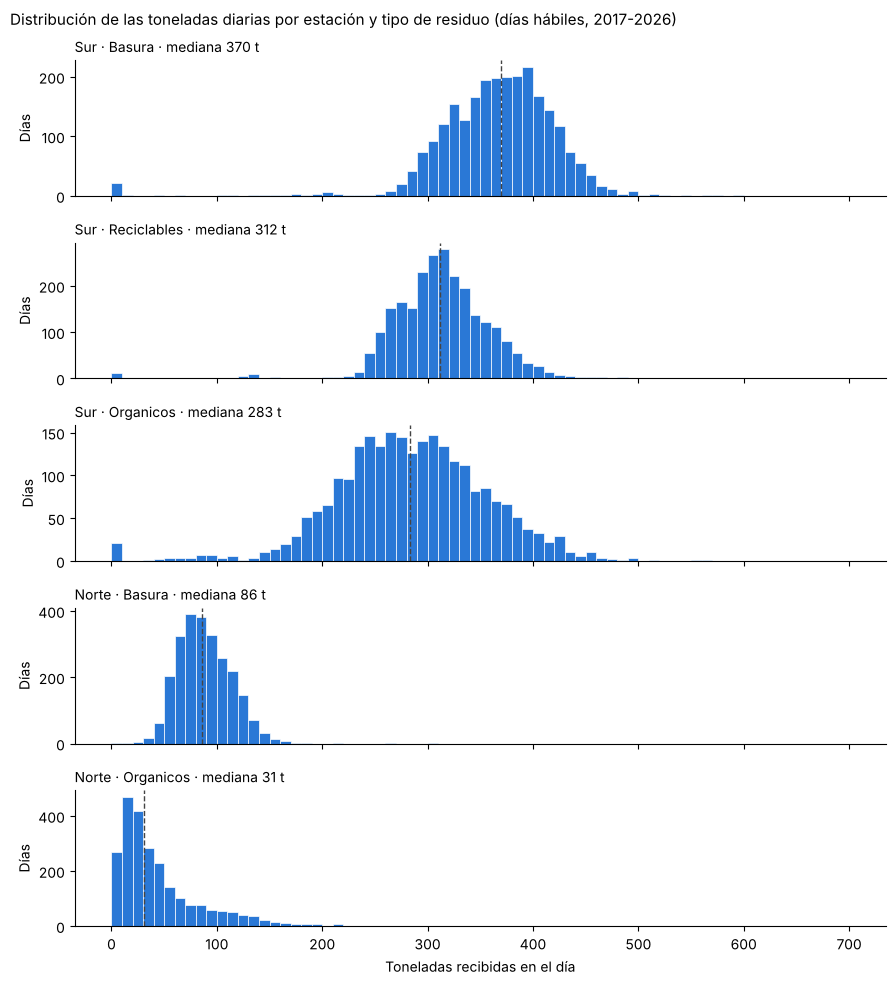

In [4]:
# Paso 4 · Gráfico de distribución de las toneladas

# Qué hacemos: un histograma por combinación, todos con el mismo eje horizontal.
# Por qué: el histograma muestra qué valores son habituales y cuáles son raros.
# Un solo histograma con todo mezclado mostraría varias "montañas" superpuestas
# (una por combinación) y no se entendería; por eso va uno por combinación.

# subplots crea 5 gráficos apilados; sharex=True les da el mismo eje horizontal,
# así se compara directamente dónde está cada combinación
fig, ejes = plt.subplots(5, 1, figsize=(9, 10), sharex=True)

for eje, comb in zip(ejes, combinaciones):
    valores = df.loc[df["combinacion"] == comb, "toneladas"]
    # bins: intervalos de 10 toneladas, de 0 a 700
    eje.hist(valores, bins=range(0, 710, 10), color="#2a78d6", edgecolor="white", linewidth=0.5)
    # Línea vertical en la mediana, para marcar el valor típico
    eje.axvline(valores.median(), color="#444444", linestyle="--", linewidth=1)
    eje.set_title(f"{comb} · mediana {valores.median():.0f} t", loc="left", fontsize=10)
    eje.set_ylabel("Días")
    eje.spines[["top", "right"]].set_visible(False)

ejes[-1].set_xlabel("Toneladas recibidas en el día")
fig.suptitle("Distribución de las toneladas diarias por estación y tipo de residuo (días hábiles, 2017-2026)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

Cada combinación tiene una distribución concentrada alrededor de su propio nivel, y las de la estación Sur están claramente separadas de las de la Norte. Los orgánicos de la Norte son los más dispersos: varían mucho a lo largo del año (se ve en el gráfico por mes). Hay unos pocos días con valores cercanos a cero en la estación Sur, probablemente días con recolección parcial; son muy pocos y se conservan, pero el modelo los va a predecir mal y conviene tenerlo en cuenta al analizar los errores.

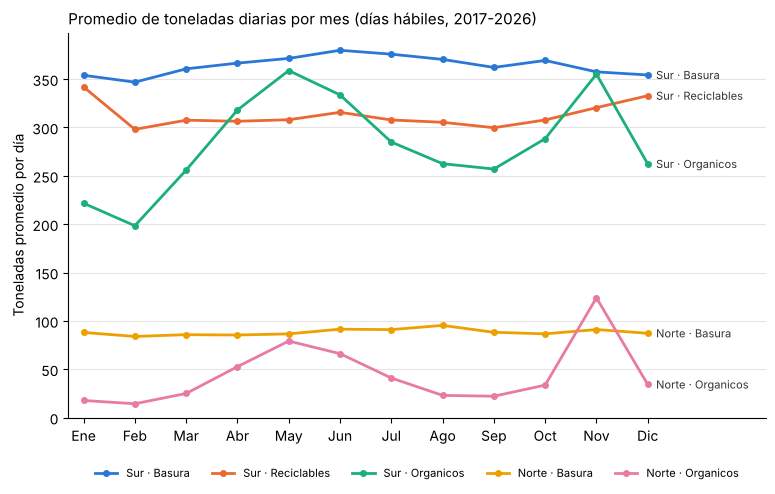

combinacion,Sur · Basura,Sur · Reciclables,Sur · Organicos,Norte · Basura,Norte · Organicos
mes,,,,,
1,354.0,342.0,222.0,88.0,18.0
2,347.0,298.0,198.0,84.0,14.0
3,361.0,307.0,256.0,86.0,25.0
4,367.0,306.0,318.0,85.0,53.0
5,371.0,308.0,359.0,87.0,79.0
6,380.0,316.0,334.0,91.0,66.0
7,376.0,308.0,285.0,91.0,41.0
8,370.0,305.0,263.0,95.0,23.0
9,362.0,300.0,257.0,88.0,22.0


In [5]:
# Paso 5 · Gráfico de promedio de toneladas por mes

# Qué hacemos: el promedio de toneladas de cada mes del año, una línea por combinación.
# Por qué: si hay meses con más o menos residuos (estacionalidad), el mes es una
# variable útil para el modelo. Promediamos todos los años juntos.

# pivot_table arma una tabla: filas = mes, columnas = combinación, valores = promedio
por_mes = df.pivot_table(index="mes", columns="combinacion", values="toneladas", aggfunc="mean")

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, eje = plt.subplots(figsize=(9, 5))
for comb, color in zip(combinaciones, colores):
    eje.plot(por_mes.index, por_mes[comb], marker="o", markersize=4, linewidth=2, color=color, label=comb)
    # Etiqueta al final de cada línea, para no depender solo del color
    eje.annotate(comb, (12, por_mes.loc[12, comb]), xytext=(6, 0), textcoords="offset points",
                 va="center", fontsize=8, color="#333333")

eje.set_xticks(range(1, 13), meses)
eje.set_xlim(0.7, 14.3)
eje.set_ylim(0, None)
eje.set_ylabel("Toneladas promedio por día")
eje.set_title("Promedio de toneladas diarias por mes (días hábiles, 2017-2026)", loc="left", fontsize=11)
eje.grid(axis="y", color="#e5e5e5")
eje.spines[["top", "right"]].set_visible(False)
eje.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=5)
plt.show()

# La tabla con los mismos valores, redondeados
por_mes[combinaciones].round(0)

Los orgánicos son el único residuo con una estacionalidad marcada: suben en primavera (mayo) y tienen su pico en noviembre, que coincide con la caída de hojas, mientras que enero y febrero son los meses más bajos. En la Norte, los orgánicos pasan de unas 14 toneladas en febrero a 124 en noviembre. La basura y los reciclables se mantienen casi constantes durante el año, con una leve suba de reciclables en diciembre y enero (fiestas). Por eso el mes es una variable útil, sobre todo combinada con el tipo de residuo: un efecto que un árbol puede captar y una regresión lineal simple no.

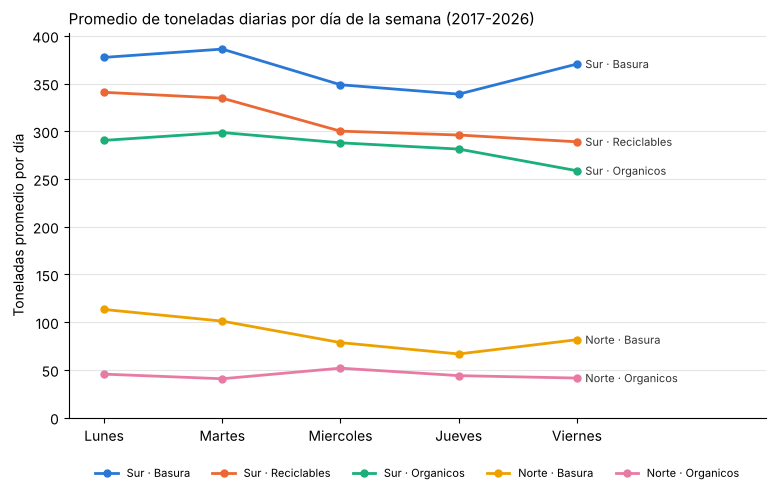

combinacion,Sur · Basura,Sur · Reciclables,Sur · Organicos,Norte · Basura,Norte · Organicos
dia_semana,,,,,
Lunes,377.0,341.0,290.0,113.0,46.0
Martes,386.0,335.0,299.0,101.0,41.0
Miercoles,349.0,300.0,288.0,79.0,52.0
Jueves,339.0,296.0,281.0,67.0,44.0
Viernes,370.0,289.0,259.0,82.0,41.0


In [6]:
# Paso 6 · Gráfico de promedio de toneladas por día de la semana

# Qué hacemos: el promedio de toneladas de cada día hábil, una línea por combinación.
# Por qué: si la carga cambia según el día, el día de la semana es una variable útil.

por_dia = df.pivot_table(index="dia_semana", columns="combinacion", values="toneladas", aggfunc="mean")
# reindex ordena los días de lunes a viernes (si no, quedarían en orden alfabético)
por_dia = por_dia.reindex(dias)

fig, eje = plt.subplots(figsize=(9, 5))
for comb, color in zip(combinaciones, colores):
    eje.plot(dias, por_dia[comb], marker="o", markersize=5, linewidth=2, color=color, label=comb)
    eje.annotate(comb, (4, por_dia.loc["Viernes", comb]), xytext=(6, 0), textcoords="offset points",
                 va="center", fontsize=8, color="#333333")

eje.set_xlim(-0.3, 5.6)
eje.set_ylim(0, None)
eje.set_ylabel("Toneladas promedio por día")
eje.set_title("Promedio de toneladas diarias por día de la semana (2017-2026)", loc="left", fontsize=11)
eje.grid(axis="y", color="#e5e5e5")
eje.spines[["top", "right"]].set_visible(False)
eje.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=5)
plt.show()

por_dia[combinaciones].round(0)

La carga es más alta al comienzo de la semana: lunes y martes son los días más fuertes en casi todas las combinaciones, y el jueves suele ser el más bajo. Es probable que el lunes acumule parte de lo que no se recolecta el fin de semana. La basura de las dos estaciones vuelve a subir el viernes, mientras que los reciclables y los orgánicos de la Sur siguen bajando. Como el patrón cambia según la combinación, el día de la semana conviene usarlo junto con la estación y el tipo de residuo.

In [7]:
# Paso 7 · Efecto de los feriados

# Qué hacemos: comparar el promedio de toneladas en feriados y en días comunes.
# Por qué: si un feriado cambia la carga, la variable "feriado" le sirve al modelo.

feriados = (df.pivot_table(index="combinacion", columns="feriado", values="toneladas", aggfunc="mean")
              .reindex(combinaciones).round(0))
feriados.columns = ["Día común", "Feriado"]
print("Días feriados en el dataset:", df["feriado"].sum())
feriados

Días feriados en el dataset: 425


,Día común,Feriado
combinacion,,
Sur · Basura,368.0,285.0
Sur · Reciclables,313.0,282.0
Sur · Organicos,286.0,230.0
Norte · Basura,88.0,101.0
Norte · Organicos,45.0,46.0


Hay 425 filas de días hábiles feriados. En la estación Sur, los feriados reciben entre 30 y 80 toneladas menos que un día común; en la Norte la diferencia es chica. El efecto existe, pero hay pocos casos, así que el modelo lo va a aprender con menos precisión que el del día o el mes.